In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
df = pd.read_csv("/content/drive/MyDrive/AI /Project/StudentsPerformance.csv")

In [6]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [7]:
print(df.shape)
df.info()
df.describe()

(1000, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [8]:
df.isnull().sum()

,0
gender,0
race/ethnicity,0
parental level of education,0
lunch,0
test preparation course,0
math score,0
reading score,0
writing score,0


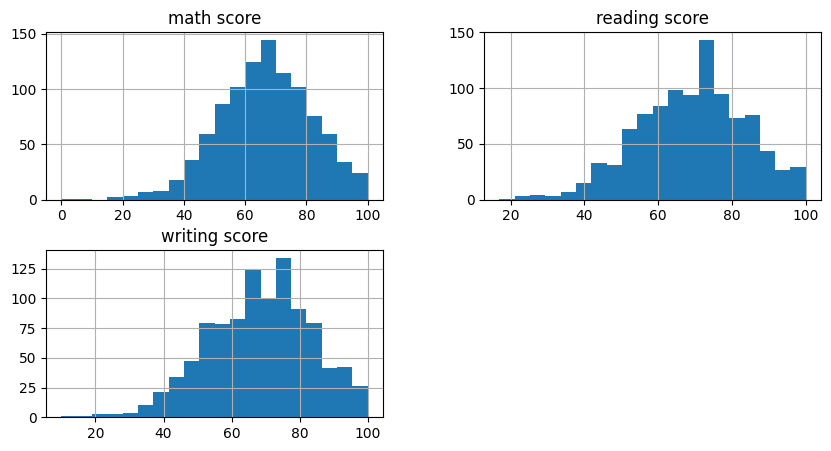

In [9]:
df[["math score", "reading score", "writing score"]].hist(
    bins=20, figsize=(10,5)
)
plt.show()

In [10]:
categorical_cols = [
    "gender",
    "race/ethnicity",
    "parental level of education",
    "lunch",
    "test preparation course"
]

for col in categorical_cols:
    print(f"\n{col.upper()}")
    print(df[col].value_counts())


GENDER
gender
female    518
male      482
Name: count, dtype: int64

RACE/ETHNICITY
race/ethnicity
group C    319
group D    262
group B    190
group E    140
group A     89
Name: count, dtype: int64

PARENTAL LEVEL OF EDUCATION
parental level of education
some college          226
associate's degree    222
high school           196
some high school      179
bachelor's degree     118
master's degree        59
Name: count, dtype: int64

LUNCH
lunch
standard        645
free/reduced    355
Name: count, dtype: int64

TEST PREPARATION COURSE
test preparation course
none         642
completed    358
Name: count, dtype: int64


In [11]:
df["average_score"] = (
    df["math score"] +
    df["reading score"] +
    df["writing score"]
) / 3

def assign_grade(avg):
    if avg >= 90:
        return "A+"
    elif avg >= 80:
        return "A"
    elif avg >= 70:
        return "B"
    elif avg >= 60:
        return "C"
    elif avg >= 50:
        return "D"
    else:
        return "F"

def assign_level(avg):
    if avg >= 90:
        return "Excellent"
    elif avg >= 80:
        return "Very Good"
    elif avg >= 70:
        return "Good"
    elif avg >= 60:
        return "Average"
    else:
        return "Poor"

df["performance_grade"] = df["average_score"].apply(assign_grade)
df["performance_level"] = df["average_score"].apply(assign_level)

performance_grade
B     261
C     256
D     182
A     146
F     103
A+     52
Name: count, dtype: int64
performance_level
Poor         285
Good         261
Average      256
Very Good    146
Excellent     52
Name: count, dtype: int64


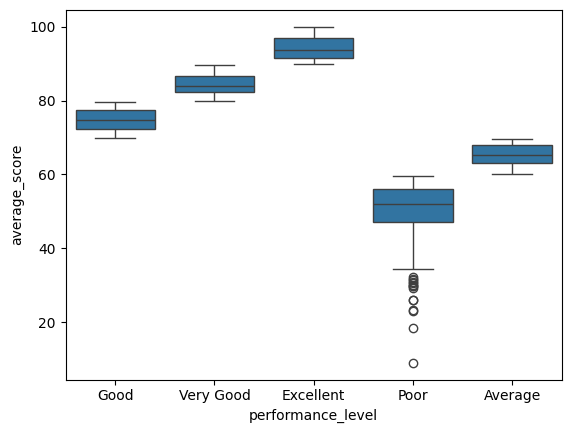

In [12]:
print(df["performance_grade"].value_counts())
print(df["performance_level"].value_counts())

sns.boxplot(x="performance_level", y="average_score", data=df)
plt.show()

In [13]:
grade_to_level = {
    "A+": "Excellent",
    "A": "Very Good",
    "B": "Good",
    "C": "Average",
    "D": "Below Average",
    "F": "Poor"
}

In [14]:
X = df[
    [
        "gender",
        "race/ethnicity",
        "parental level of education",
        "lunch",
        "test preparation course",
        "math score",
        "reading score",
        "writing score"
    ]
]

y_grade = df["performance_grade"]

In [15]:
from sklearn.preprocessing import LabelEncoder

X_encoded = X.copy()
le_dict = {}

for col in X_encoded.select_dtypes(include="object").columns:
    le = LabelEncoder()
    X_encoded[col] = le.fit_transform(X_encoded[col])
    le_dict[col] = le

le_grade = LabelEncoder()
y_grade_enc = le_grade.fit_transform(y_grade)

In [16]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y_grade_enc,
    test_size=0.2,
    random_state=42,
    stratify=y_grade_enc
)

In [17]:
from sklearn.svm import SVC

svm_model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale"
)

svm_model.fit(X_train, y_train)

SVC()

In [18]:
from sklearn.ensemble import GradientBoostingClassifier

gb_model = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gb_model.fit(X_train, y_train)

GradientBoostingClassifier(learning_rate=0.05, n_estimators=200,
                           random_state=42)

In [19]:
# SVM predictions
svm_pred_enc = svm_model.predict(X_test)
svm_pred_grade = le_grade.inverse_transform(svm_pred_enc)
svm_pred_level = [grade_to_level[g] for g in svm_pred_grade]

# Gradient Boosting predictions
gb_pred_enc = gb_model.predict(X_test)
gb_pred_grade = le_grade.inverse_transform(gb_pred_enc)
gb_pred_level = [grade_to_level[g] for g in gb_pred_grade]

In [20]:
from sklearn.metrics import accuracy_score, classification_report

print("SVM Accuracy:", accuracy_score(y_test, svm_pred_enc))
print(classification_report(
    le_grade.inverse_transform(y_test),
    svm_pred_grade
))

print("\nGradient Boosting Accuracy:", accuracy_score(y_test, gb_pred_enc))
print(classification_report(
    le_grade.inverse_transform(y_test),
    gb_pred_grade
))

SVM Accuracy: 0.925
              precision    recall  f1-score   support

           A       0.84      0.93      0.89        29
          A+       1.00      0.50      0.67        10
           B       0.95      1.00      0.97        52
           C       0.98      0.98      0.98        51
           D       0.86      0.97      0.91        37
           F       1.00      0.71      0.83        21

    accuracy                           0.93       200
   macro avg       0.94      0.85      0.87       200
weighted avg       0.93      0.93      0.92       200


Gradient Boosting Accuracy: 0.95
              precision    recall  f1-score   support

           A       0.96      0.93      0.95        29
          A+       0.91      1.00      0.95        10
           B       0.98      0.98      0.98        52
           C       0.96      0.96      0.96        51
           D       0.89      0.92      0.91        37
           F       0.95      0.90      0.93        21

    accuracy           

In [21]:
comparison = pd.DataFrame({
    "Actual Grade": le_grade.inverse_transform(y_test),
    "SVM Predicted Grade": svm_pred_grade,
    "SVM Performance Level": svm_pred_level,
    "GB Predicted Grade": gb_pred_grade,
    "GB Performance Level": gb_pred_level
})

comparison.head()

,Actual Grade,SVM Predicted Grade,SVM Performance Level,GB Predicted Grade,GB Performance Level
0,D,D,Below Average,D,Below Average
1,A,A,Very Good,A,Very Good
2,D,D,Below Average,D,Below Average
3,A+,A+,Excellent,A+,Excellent
4,F,F,Poor,F,Poor


In [22]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

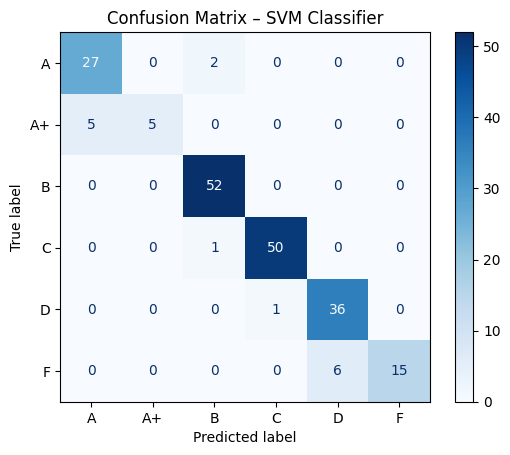

In [23]:
cm_svm = confusion_matrix(y_test, svm_pred_enc)

disp_svm = ConfusionMatrixDisplay(
    confusion_matrix=cm_svm,
    display_labels=le_grade.classes_
)

disp_svm.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix – SVM Classifier")
plt.show()

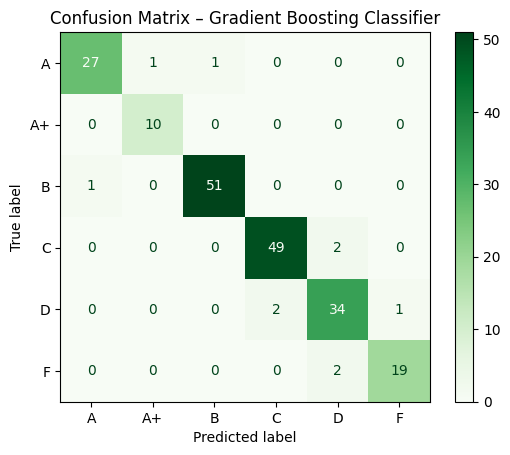

In [24]:
cm_gb = confusion_matrix(y_test, gb_pred_enc)

disp_gb = ConfusionMatrixDisplay(
    confusion_matrix=cm_gb,
    display_labels=le_grade.classes_
)

disp_gb.plot(cmap="Greens", values_format="d")
plt.title("Confusion Matrix – Gradient Boosting Classifier")
plt.show()

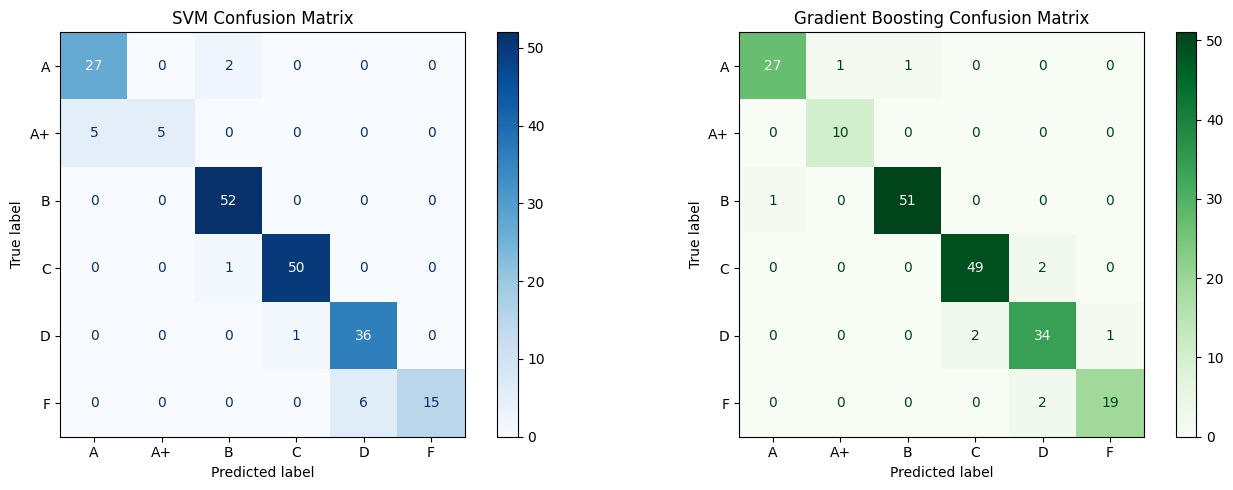

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay(
    cm_svm, display_labels=le_grade.classes_
).plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("SVM Confusion Matrix")

ConfusionMatrixDisplay(
    cm_gb, display_labels=le_grade.classes_
).plot(ax=axes[1], cmap="Greens", values_format="d")
axes[1].set_title("Gradient Boosting Confusion Matrix")

plt.tight_layout()
plt.show()

In [26]:
# Example grade mapping (use the same mapping you used in training)
grade_mapping = {
    'F': 0,
    'D': 1,
    'C': 2,
    'B': 3,
    'A': 4,
    'A+': 5
}

y_test_string_grades = le_grade.inverse_transform(y_test)
y_pred_string_grades = le_grade.inverse_transform(gb_pred_enc)

y_test_encoded = pd.Series(y_test_string_grades).map(grade_mapping)
y_pred_encoded = pd.Series(y_pred_string_grades).map(grade_mapping)


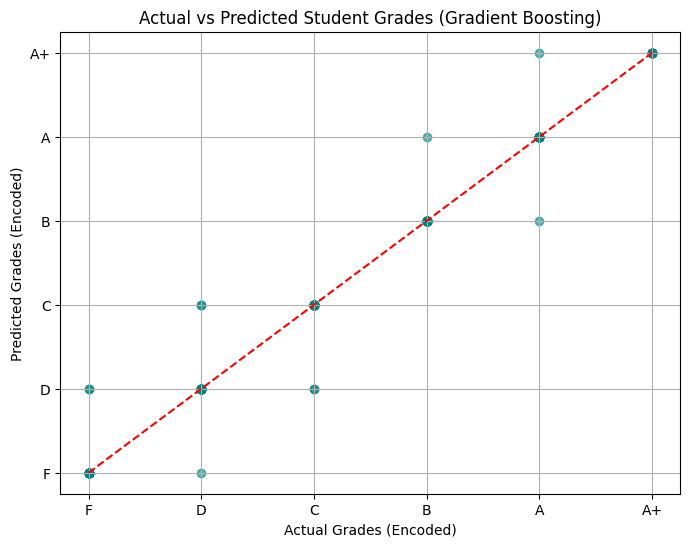

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(y_test_encoded, y_pred_encoded, alpha=0.6, color='teal')
plt.plot([0, 5], [0, 5], color='red', linestyle='--')  # perfect prediction line

plt.xlabel("Actual Grades (Encoded)")
plt.ylabel("Predicted Grades (Encoded)")
plt.title("Actual vs Predicted Student Grades (Gradient Boosting)")

plt.xticks(range(6), ['F', 'D', 'C', 'B', 'A', 'A+'])
plt.yticks(range(6), ['F', 'D', 'C', 'B', 'A', 'A+'])

plt.grid(True)
plt.show()
